# Galerkin法はなぜ有限要素法につながるのか

## 概要

Galerkin法は、近似解と同じ関数空間で方程式を検査する方法である。領域を要素に分け、局所的な区分多項式を基底に選ぶと、標準的なGalerkin有限要素法になる。一次元Poisson方程式を使い、弱形式から要素行列の組み立てまでを計算する。Pythonで近似解と誤差も確認する。

### 実行環境

仮想環境・カーネルは **wa-src(3.14.6)**、Pythonは **3.14.6** である。ライブラリの版は次のセルで表示する。上から順に実行すると、図をノートブック内に表示し、`102_nb_files`にSVG形式で保存する。数値表示は有効数字3桁とし、計算途中では丸めない。

In [1]:
import platform
import sys
from pathlib import Path
from pprint import pprint

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
import sympy as sp
from IPython.display import Latex, display
from matplotlib.ticker import FuncFormatter, NullFormatter
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import spsolve

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

assert sys.version_info[:3] == (3, 14, 6), 'wa-src(3.14.6)を選択する'
print('環境: wa-src(3.14.6)')
print('Python:', platform.python_version())
print('OS:', platform.system(), platform.release())
for name, module in [('NumPy', np), ('SciPy', scipy),
                     ('SymPy', sp), ('Matplotlib', matplotlib)]:
    print(f'{name}: {module.__version__}')

# 通常はノートブックの隣へ保存する。リポジトリ直下からの実行にも対応する。
workdir = Path.cwd()
article_dir = workdir / 'rec' / 'cae' / '102'
output_dir = (article_dir if article_dir.is_dir() else workdir) / '102_nb_files'
output_dir.mkdir(exist_ok=True)

def sig(value):
    """末尾のゼロも残し、有効数字3桁で表示する。"""
    # 表示時のみ微小な浮動小数点誤差を整え、3桁へ丸める。
    return f'{float(f"{float(value):.14g}"):#.3g}'

np.set_printoptions(formatter={'float_kind': sig})
plt.rcParams.update({'font.size': 11, 'svg.fonttype': 'none'})

def save_figure(fig, filename):
    """軸の数値を整え、SVGの保存とNotebook上の表示を行う。"""
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            axis.set_major_formatter(FuncFormatter(lambda value, pos: sig(value)))
            axis.set_minor_formatter(NullFormatter())
    fig.savefig(output_dir / filename, format='svg', bbox_inches='tight')
    plt.show()
    plt.close(fig)

環境: wa-src(3.14.6)
Python: 3.14.6
OS: Darwin 25.5.0
NumPy: 2.5.4
SciPy: 1.18.1
SymPy: 1.14.0
Matplotlib: 3.11.2


## 1. 微分方程式を弱形式にする

対象は両端の値を固定した問題である。

$$
\displaystyle -u''(x)=2\quad(0\lt x\lt1),\qquad u(0)=u(1)=0.
$$

積分すると$u'=-2x+C_1$、$u=-x^2+C_1x+C_2$となる。境界条件から$C_2=0$、$C_1=1$なので、厳密解は$u=x(1-x)$である。

両端でゼロになる試験関数$v$を掛け、部分積分する。

$$
\displaystyle
\begin{aligned}
\int_0^1(-u'')v\,dx&=\int_0^1 2v\,dx,\\
-[u'v]_0^1+\int_0^1u'v'\,dx&=\int_0^1 2v\,dx,\\
\int_0^1u'v'\,dx&=\int_0^1 2v\,dx.
\end{aligned}
$$

最後の式が弱形式である。$V=H_0^1(0,1)$を、関数と弱微分の二乗が積分可能で両端の値がゼロとなる空間とし、すべての$v\in V$に対してこの式を満たす$u\in V$を求める。二階微分が不要なので、傾きが節点で不連続な折れ線も近似に使える。弱形式の導出は[文献1](https://jsdokken.com/dolfinx-tutorial/stable/chapter1/fundamentals.html)に沿う。

## 2. Galerkin法で未知数を有限個にする

$V_h=\operatorname{span}\{\phi_1,\ldots,\phi_{n-1}\}\subset V$を選び、近似解を展開する。試験関数も同じ$V_h$から選ぶ点がGalerkin法の条件である。

$$
\displaystyle
\begin{aligned}
u_h&=\sum_{j=1}^{n-1}U_j\phi_j,\\
\int_0^1\left(\sum_j U_j\phi_j'\right)\phi_i'\,dx
&=\int_0^1 2\phi_i\,dx,\\
\sum_j\underbrace{\left(\int_0^1\phi_i'\phi_j'\,dx\right)}_{K_{ij}}U_j
&=\underbrace{\int_0^1 2\phi_i\,dx}_{F_i},\\
\mathbf{K}\mathbf{U}&=\mathbf{F}.
\end{aligned}
$$

厳密解と近似解の弱形式を引くと、$\int_0^1(u-u_h)'v_h'\,dx=0$となる。これはGalerkin直交性であり、各点で誤差がゼロという意味ではない。

## 3. 局所的な基底を選ぶと有限要素法になる

区間を$n$等分し、$h=1/n$、$x_i=ih$とする。内部節点$i$で1、それ以外の節点で0となる基底を使う。

$$
\displaystyle
\phi_i(x)=\begin{cases}
(x-x_{i-1})/h&x_{i-1}\le x\le x_i,\\
(x_{i+1}-x)/h&x_i\lt x\le x_{i+1},\\
0&\text{otherwise}.
\end{cases}
$$

$\phi_i(x_j)=\delta_{ij}$なので$u_h(x_i)=U_i$である。基底が重なるのは隣接節点だけで、$|i-j|>1$なら$K_{ij}=0$となる。要素、局所基底、節点の接続を指定したものが、この一次要素による有限要素空間である。[文献2](https://hplgit.github.io/INF5620/doc/pub/H14/fem/html/._main_fem004.html)に基底の構成が詳しい。

Galerkin法自体は基底を限定しない。全域に広がる三角関数なども使える。有限要素法につながるのは、弱形式に加えて、要素ごとの多項式を接続する選択をしたためである。私は、基底の形と行列のゼロの位置を並べると、この違いを理解しやすいと感じる。

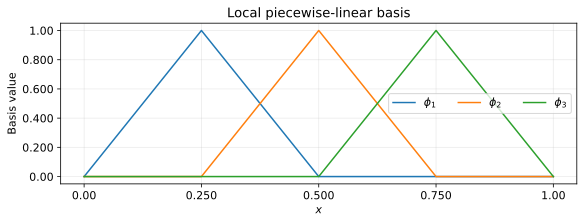

In [2]:
# 4要素の場合の内部基底を描く。両端の自由度は境界条件で固定する。
n = 4
nodes = np.linspace(0, 1, n + 1)
grid = np.linspace(0, 1, 801)
h = 1 / n

fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
for i in range(1, n):
    phi = np.maximum(1 - np.abs(grid - nodes[i]) / h, 0)
    ax.plot(grid, phi, label=rf'$\phi_{i}$')
ax.set(xlabel='$x$', ylabel='Basis value', title='Local piecewise-linear basis')
ax.set_xticks(nodes)
ax.legend(ncol=3)
ax.grid(alpha=0.250)
save_figure(fig, '01_basis.svg')

## 4. 要素行列を積分する

一つの要素を$[a,a+h]$とし、$s=x-a$と置く。局所形状関数は$N_1=1-s/h$、$N_2=s/h$で、微分は$N_1'=-1/h$、$N_2'=1/h$である。

$$
\displaystyle
\begin{aligned}
K_{11}^{(e)}=K_{22}^{(e)}&=\int_0^h\frac{1}{h^2}\,ds=\frac{1}{h},\\
K_{12}^{(e)}=K_{21}^{(e)}&=\int_0^h\frac{-1}{h^2}\,ds=-\frac{1}{h},\\
F_1^{(e)}&=2\int_0^h(1-s/h)\,ds=2[h-h/2]=h,\\
F_2^{(e)}&=2\int_0^h s/h\,ds=2[h/2]=h,\\
\mathbf{K}^{(e)}&=\frac{1}{h}\begin{bmatrix}1&-1\\-1&1\end{bmatrix},
\quad\mathbf{F}^{(e)}=h\begin{bmatrix}1\\1\end{bmatrix}.
\end{aligned}
$$

SymPyでも積分し、数式を`display()`で表示する。

In [3]:
s, he = sp.symbols('s h', positive=True)
shape = sp.Matrix([1 - s / he, s / he])
derivative = shape.diff(s)
element_k = sp.integrate(derivative * derivative.T, (s, 0, he))
element_f = sp.integrate(2 * shape, (s, 0, he))

display(Latex(r'$$\displaystyle \mathbf{K}^{(e)}=' + sp.latex(element_k) + r'$$'))
display(Latex(r'$$\displaystyle \mathbf{F}^{(e)}=' + sp.latex(element_f) + r'$$'))

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

## 5. 全体行列を組み立てて解く

要素$e$の局所番号$(1,2)$を全体節点$(e,e+1)$に対応させ、共有する成分へ加算する。内部節点には二要素が接続するため、$K_{ii}=2/h$、$K_{i,i\pm1}=-1/h$、$F_i=2h$となる。$n=4$で両端の既知値を除くと、次の連立方程式になる。

$$
\displaystyle
\begin{bmatrix}8&-4&0\\-4&8&-4\\0&-4&8\end{bmatrix}
\begin{bmatrix}U_1\\U_2\\U_3\end{bmatrix}
=\begin{bmatrix}1/2\\1/2\\1/2\end{bmatrix}.
$$

第1式と第3式の差から$U_1=U_3$、第2式から$U_2=U_1+1/16$となる。第1式へ代入すると$4U_1-1/4=1/2$なので、$U_1=U_3=3/16$、$U_2=1/4$である。

内部の剛性行列、荷重ベクトル、全節点の解:
array([[8.00, -4.00, 0.00],
       [-4.00, 8.00, -4.00],
       [0.00, -4.00, 8.00]])
array([0.500, 0.500, 0.500])
array([0.00, 0.188, 0.250, 0.188, 0.00])
{'離散残差の最大絶対値': '1.11e-16'}


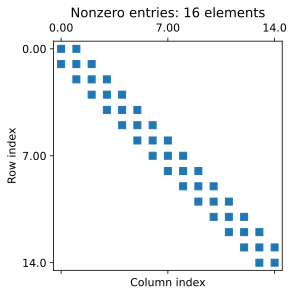

In [4]:
def solve_fem(n):
    """-u''=2、両端ゼロの問題を一様メッシュの一次要素で解く。"""
    nodes = np.linspace(0, 1, n + 1)
    stiffness = lil_matrix((n + 1, n + 1), dtype=float)
    load = np.zeros(n + 1)

    for e in range(n):
        length = nodes[e + 1] - nodes[e]
        local_k = np.array([[1, -1], [-1, 1]]) / length
        local_f = length * np.ones(2)
        indices = [e, e + 1]

        # 共有節点への寄与を上書きせず加算する。
        for a, i in enumerate(indices):
            load[i] += local_f[a]
            for b, j in enumerate(indices):
                stiffness[i, j] += local_k[a, b]

    # 境界値がゼロなので、内部成分だけを取り出せばよい。
    interior_k = stiffness.tocsr()[1:-1, 1:-1]
    interior_f = load[1:-1]
    values = np.zeros(n + 1)
    values[1:-1] = spsolve(interior_k, interior_f)
    return nodes, values, interior_k, interior_f

nodes, values, stiffness, load = solve_fem(4)
print('内部の剛性行列、荷重ベクトル、全節点の解:')
pprint(stiffness.toarray())
pprint(load)
pprint(values)

# 手計算の解と、離散方程式を満たすことを確認する。
np.testing.assert_allclose(values, [0, 3 / 16, 1 / 4, 3 / 16, 0], atol=1e-14)
np.testing.assert_allclose(stiffness @ values[1:-1], load, atol=1e-14)
residual = stiffness @ values[1:-1] - load
pprint({'離散残差の最大絶対値': sig(np.max(np.abs(residual)))})

fig, ax = plt.subplots(figsize=(5, 4), layout='constrained')
_, _, matrix16, _ = solve_fem(16)
ax.spy(matrix16, markersize=7)
ax.set(xlabel='Column index', ylabel='Row index', title='Nonzero entries: 16 elements')
ax.set_xticks([0, 7, 14])
ax.set_yticks([0, 7, 14])
save_figure(fig, '02_sparsity.svg')

この例では節点値が厳密解と一致するが、節点間には誤差が残る。一般の方程式でも節点値が一致するわけではない。図は解、導関数、誤差の順である。折れ線の二階微分を要素内部だけで評価すると節点での傾きの跳びを落とすため、元の微分方程式の残差を正しく検査できない。

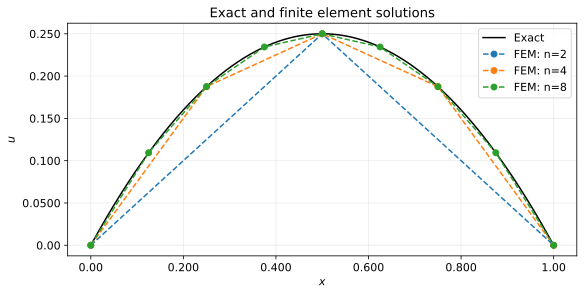

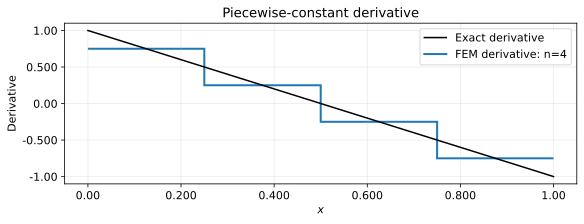

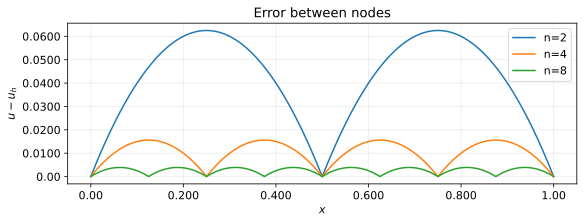

In [5]:
def exact(x):
    return x * (1 - x)

grid = np.linspace(0, 1, 1001)
fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
ax.plot(grid, exact(grid), color='black', label='Exact')
for n in (2, 4, 8):
    nodes, values, _, _ = solve_fem(n)
    ax.plot(nodes, values, 'o--', label=f'FEM: n={n}')
ax.set(xlabel='$x$', ylabel='$u$', title='Exact and finite element solutions')
ax.legend()
ax.grid(alpha=0.250)
save_figure(fig, '03_solution.svg')

nodes, values, _, _ = solve_fem(4)
slopes = np.diff(values) / np.diff(nodes)
fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
ax.plot(grid, 1 - 2 * grid, color='black', label="Exact derivative")
ax.stairs(slopes, nodes, baseline=None, label='FEM derivative: n=4', linewidth=2)
ax.set(xlabel='$x$', ylabel="Derivative", title='Piecewise-constant derivative')
ax.legend()
ax.grid(alpha=0.250)
save_figure(fig, '04_derivative.svg')

fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
for n in (2, 4, 8):
    nodes, values, _, _ = solve_fem(n)
    error = exact(grid) - np.interp(grid, nodes, values)
    ax.plot(grid, error, label=f'n={n}')
ax.set(xlabel='$x$', ylabel='$u-u_h$', title='Error between nodes')
ax.legend()
ax.grid(alpha=0.250)
save_figure(fig, '05_error.svg')

## 6. 分割を細かくしたときの誤差

この問題の内部方程式は$2U_i-U_{i-1}-U_{i+1}=2h^2$である。$U_i=x_i(1-x_i)$を代入すると左辺は$2h^2$となり、境界条件も満たす。このため、$u_h$は厳密解の節点を結ぶ折れ線になる。

要素左端からの距離を$s$とすると、$u(a+s)=u(a)+(1-2a)s-s^2$、$u_h(a+s)=u(a)+(1-2a-h)s$なので、誤差は$e=s(h-s)$、導関数の誤差は$e'=h-2s$である。

$$
\displaystyle
\begin{aligned}
\|e\|_{L^2}^2
&=n\int_0^h(h^2s^2-2hs^3+s^4)\,ds\\
&=n(h^5/3-h^5/2+h^5/5)=h^4/30,\\
|e|_{H^1}^2
&=n\int_0^h(h^2-4hs+4s^2)\,ds\\
&=n(h^3-2h^3+4h^3/3)=h^2/3.
\end{aligned}
$$

したがって$\|e\|_{L^2}=h^2/\sqrt{30}$、$|e|_{H^1}=h/\sqrt{3}$である。後者は導関数の誤差を測る半ノルムである。数値積分には各要素で3点Gauss積分を使う。二乗誤差は4次以下なので、丸め誤差を除いて正確に積分できる。

[{'n': 4,
  'h': '0.250',
  'L2': '0.0114',
  'H1 seminorm': '0.144',
  'p(L2)': '-',
  'p(H1)': '-'},
 {'n': 8,
  'h': '0.125',
  'L2': '0.00285',
  'H1 seminorm': '0.0722',
  'p(L2)': '2.00',
  'p(H1)': '1.00'},
 {'n': 16,
  'h': '0.0625',
  'L2': '0.000713',
  'H1 seminorm': '0.0361',
  'p(L2)': '2.00',
  'p(H1)': '1.00'},
 {'n': 32,
  'h': '0.0312',
  'L2': '0.000178',
  'H1 seminorm': '0.0180',
  'p(L2)': '2.00',
  'p(H1)': '1.00'},
 {'n': 64,
  'h': '0.0156',
  'L2': '4.46e-05',
  'H1 seminorm': '0.00902',
  'p(L2)': '2.00',
  'p(H1)': '1.00'}]


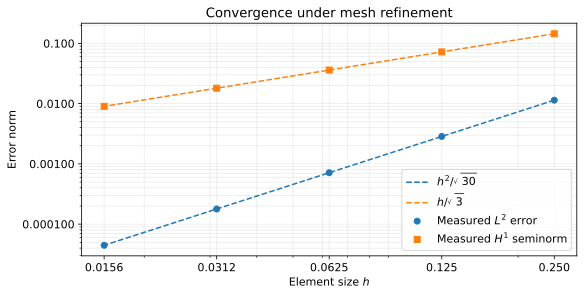

In [6]:
def measure_errors(nodes, values):
    """要素ごとに積分し、節点の導関数の不連続をまたがないようにする。"""
    points, weights = np.polynomial.legendre.leggauss(3)
    l2_squared = 0
    h1_squared = 0
    for i, length in enumerate(np.diff(nodes)):
        # [-1, 1]の積分点を実際の要素へ写す。
        t = (points + 1) / 2
        xq = nodes[i] + length * t
        uq = (1 - t) * values[i] + t * values[i + 1]
        slope = (values[i + 1] - values[i]) / length
        l2_squared += length / 2 * np.dot(weights, (exact(xq) - uq) ** 2)
        h1_squared += length / 2 * np.dot(weights, (1 - 2 * xq - slope) ** 2)
    return np.sqrt(l2_squared), np.sqrt(h1_squared)

counts = np.array([4, 8, 16, 32, 64])
sizes = 1 / counts
errors = np.array([measure_errors(*solve_fem(int(n))[:2]) for n in counts])
theory_l2 = sizes ** 2 / np.sqrt(30)
theory_h1 = sizes / np.sqrt(3)
np.testing.assert_allclose(errors[:, 0], theory_l2, rtol=1e-10)
np.testing.assert_allclose(errors[:, 1], theory_h1, rtol=1e-10)

# p = log(E_h / E_{h/2}) / log(2)で観測収束次数を求める。
rates = np.log(errors[:-1] / errors[1:]) / np.log(2)
rows = []
for i, n in enumerate(counts):
    rows.append({'n': int(n), 'h': sig(sizes[i]),
                 'L2': sig(errors[i, 0]), 'H1 seminorm': sig(errors[i, 1]),
                 'p(L2)': '-' if i == 0 else sig(rates[i - 1, 0]),
                 'p(H1)': '-' if i == 0 else sig(rates[i - 1, 1])})
pprint(rows, sort_dicts=False)

fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
ax.loglog(sizes, theory_l2, '--', color='C0', label=r'$h^2/\sqrt{30}$')
ax.loglog(sizes, theory_h1, '--', color='C1', label=r'$h/\sqrt{3}$')
ax.loglog(sizes, errors[:, 0], 'o', color='C0', label=r'Measured $L^2$ error')
ax.loglog(sizes, errors[:, 1], 's', color='C1', label=r'Measured $H^1$ seminorm')
ax.set(xlabel='Element size $h$', ylabel='Error norm', title='Convergence under mesh refinement')
ax.set_xticks(sizes)
ax.legend()
ax.grid(which='both', alpha=0.250)
save_figure(fig, '06_convergence.svg')

## 結論

この記事では、弱形式にGalerkin法を適用し、局所的な区分多項式を基底に選ぶことで有限要素法が得られることを確認した。

弱形式は必要な微分の階数を下げ、局所基底は疎な行列と要素ごとの計算を可能にする。今回の一次要素では、解の$L^2$誤差は$h^2$、導関数の誤差は$h$に比例した。これは一様分割と滑らかな厳密解を持つ今回の問題の結果である。

参考文献は、1. Langtangen・Logg著、Dokken改訂「Solving the Poisson equation」、2. Langtangen著「Introduction to finite element methods」の「Finite element basis functions」である。本文中のリンク先を参照。